# Family Kalman filter — SVI + dynamic B-spline correction Δ(k, t)

**Motivation (Issue #3):** The two-pass model's `Δ(k)` is a time-average, so it cannot follow
intraday drift in level/skew/curvature. This notebook makes the correction *dynamic*:

$$\text{IV}(k, T, t) = \underbrace{\text{SVI}(k, T;\, \theta(t))}_{\text{global smile}} + \underbrace{\sum_{i=1}^{n} \beta_i(t)\,B_i(k)}_{\Delta(k,\,t)}$$

where $\{B_i\}$ are cubic B-spline basis functions with **fixed knots** in $k$-space and $[\theta, \beta]$
evolve jointly in a single augmented EKF.  B-splines have local support and form a partition of unity,
so each $\beta_i$ controls an independent region of the smile with no leakage to distant strikes.

| Component | Dim | Role |
|-----------|-----|------|
| $\theta$ (SVI) | 5 | Global smile shape (a, b, ρ, m, σ) |
| $\beta$ (B-spline) | 8 | Dynamic residual correction Δ(k, t) |
| **Total state** | **13** | Jointly updated on every quote tick |

In [25]:
import importlib as imp
import os
import sys
from datetime import date, datetime

import matplotlib.pyplot as plt
import numpy as np
import plotly.graph_objects as go
import polars as pl
import polars.selectors as cs
from plotly.subplots import make_subplots

project_root = os.path.abspath("/Users/elie/Documents/GitHub/quant_data/")
if project_root not in sys.path:
    sys.path.insert(0, project_root)

sys.path.insert(
    0, os.path.join(os.path.dirname(os.path.abspath("__file__")), "..", "shared_functions")
)
sys.path.insert(0, os.path.dirname(os.path.abspath("__file__")))

os.environ["QUANTDATA_RAW_DATA"] = "!/quantdata/raw"
os.environ["QUANTDATA_TRAINING_DATA"] = "!/quantdata/training"
os.environ["QUANTDATA_PROCESSING_DATA"] = "!/quantdata/processing"
os.environ["QUANTDATA_CACHE_MODE"] = "on"
os.environ["QUANTDATA_TEST_MODE"] = "0"

import quantdata as _

imp.reload(_)
import quantdata.biz_calendar as _

imp.reload(_)
import quantdata.massive.client as _

imp.reload(_)
import quantdata.massive.options.contracts as _

imp.reload(_)

import surface_kalman_filters
import surface_model

import personal.shared_functions.kalman_filters as kalman_filters
import personal.shared_functions.utils as utils
from personal.shared_functions.iv_evaluation import evaluate_kalman_iv
from quantdata.massive.client import MassiveClient
from quantdata.massive.taq import TAQMatchConfig, match_taq

/Users/elie/Documents/GitHub/quant_data/quantdata/__init__.py:212: UserWarning: Using cache mode 'on' as specified in environment variable QUANTDATA_CACHE_MODE.


## Config — SVI backbone + B-spline residual basis

In [26]:
from scipy.interpolate import BSpline

# ── SVI backbone (pass-1 component, same as spline notebook) ──────────────────
svi_cfg = surface_model.SurfaceModelConfig(
    model=surface_model.SVI_SLICE_MODEL,
    Q_scale=0.05,
    Q_structure="scaled_identity",
    P0_scale=1.0,
)

# ── B-spline residual basis (β component) ─────────────────────────────────────
N_BASIS = 8  # number of cubic B-spline basis functions
K_MIN = -0.30  # left boundary of the knot domain (log-moneyness)
K_MAX = 0.15  # right boundary
DEGREE = 3  # spline degree (cubic)
BETA_Q_SCALE = 1e-4  # process noise per step for each βᵢ
BETA_P0_SCALE = 0.01  # initial uncertainty for β (starts near zero but uncertain)

# Build the clamped knot vector: (degree+1) repeated at each boundary,
# with (N_BASIS - degree - 1) uniformly spaced interior knots.
_n_interior = N_BASIS - DEGREE - 1
_interior = np.linspace(K_MIN, K_MAX, _n_interior + 2)[1:-1]
bspline_knots = np.r_[
    np.repeat(K_MIN, DEGREE + 1),
    _interior,
    np.repeat(K_MAX, DEGREE + 1),
]
bspline_interior_knots = _interior  # for plotting knot positions
bspline_klo = float(bspline_knots[DEGREE])
bspline_khi = float(bspline_knots[-(DEGREE + 1)])

n_total = svi_cfg.n_params + N_BASIS

print(f"SVI backbone      : {svi_cfg.model.name}  |  n_params={svi_cfg.n_params}")
print(f"Knot vector       : {bspline_knots.round(3)}")
print(f"Interior knots    : {bspline_interior_knots.round(3)}")
print(f"Valid domain      : [{bspline_klo:.3f}, {bspline_khi:.3f}]")
print(f"Total state       : dim={n_total}  (SVI {svi_cfg.n_params} + β {N_BASIS})")
print(f"β Q_scale         : {BETA_Q_SCALE}  |  β P0_scale: {BETA_P0_SCALE}")

SVI backbone      : svi_slice  |  n_params=5
Knot vector       : [-0.3  -0.3  -0.3  -0.3  -0.21 -0.12 -0.03  0.06  0.15  0.15  0.15  0.15]
Interior knots    : [-0.21 -0.12 -0.03  0.06]
Valid domain      : [-0.300, 0.150]
Total state       : dim=13  (SVI 5 + β 8)
β Q_scale         : 0.0001  |  β P0_scale: 0.01


## Data loading

In [27]:
df_tickers = pl.read_csv("../spy_options_tickers.csv")

In [28]:
trade_date = date(2024, 1, 3)
client = MassiveClient()
df_spy = client.fetch_trades("SPY", trade_date)

## Build IV observation stream

In [29]:
imp.reload(surface_kalman_filters)
imp.reload(surface_model)

df_quotes_iv, df_trades_iv = surface_kalman_filters.build_iv_observations(
    df_tickers=df_tickers,
    trade_date=trade_date,
    df_spy=df_spy,
    min_trades=100,
    simple=False,
    # discount_factor_clip=(1.0, 1.0),
)
print(f"Quotes: {df_quotes_iv.shape[0]:,} rows, {df_quotes_iv['strike'].n_unique()} strikes")
print(f"Trades: {df_trades_iv.shape[0]:,} rows")
df_quotes_iv.head()

Skipping O:SPY240105C00481000: 46 bad quotes
Skipping O:SPY240105C00482000: 64 bad quotes
Skipping O:SPY240105C00483000: 842 bad quotes
Skipping O:SPY240105C00484000: 2129 bad quotes
Skipping O:SPY240105C00485000: 3888 bad quotes
Skipping O:SPY240105P00462500: 17 bad quotes
Expiry 2024-01-05: implied forward from 13 strike(s)
Quotes: 2,115,510 rows, 25 strikes
Trades: 74,099 rows


ts_ns,strike,is_call,log_moneyness,T,observed_iv,bid_iv,ask_iv,R_iv,bid_price,ask_price,forward
"datetime[ns, America/New_York]",f64,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64
2024-01-03 09:30:00.006781440 EST,479.0,true,0.018053,0.006217,0.13695,0.134075,0.139497,0.000007,0.09,0.11,470.43
2024-01-03 09:30:00.008294144 EST,471.0,false,0.001211,0.006217,0.127732,0.126371,0.129092,0.000002,2.17,2.21,470.43
2024-01-03 09:30:00.008340992 EST,479.0,true,0.018053,0.006217,0.138195,0.131123,0.144509,0.000045,0.08,0.13,470.43
2024-01-03 09:30:00.008425216 EST,477.0,true,0.013869,0.006217,0.138423,0.132129,0.144187,0.000036,0.21,0.29,470.43
2024-01-03 09:30:00.008425216 EST,478.0,true,0.015964,0.006217,0.137421,0.131226,0.143125,0.000035,0.13,0.19,470.43


In [30]:
# OTM filter: keeps puts (k < 0) and calls (k ≥ 0) only.
# ITM options have wide, unreliable spreads — exclude from training.
df_quotes_otm = df_quotes_iv.filter(
    (pl.col("is_call") & (pl.col("log_moneyness") >= 0))
    | (~pl.col("is_call") & (pl.col("log_moneyness") < 0))
)
print(f"Quotes before OTM filter: {df_quotes_iv.shape[0]:,}  →  after: {df_quotes_otm.shape[0]:,}")

Quotes before OTM filter: 2,115,510  →  after: 978,523


In [31]:
# df_quotes_otm = df_quotes_iv

## Family Kalman filter — implementation

State: `s = [θ_SVI (5), β (N_BASIS)]`

Observation: `h(s, k, T) = SVI(θ_SVI, k, T) + β · B(k)`  
Jacobian:    `H = [H_SVI | B(k)]`   where `B(k) = [B₀(k), …, Bₙ(k)]` is the B-spline basis row.

The SVI part is nonlinear → EKF.  The β part is linear in B-spline coefficients → exact Kalman update.
Both are handled uniformly by the same `_kf_step` with the augmented H.

In [32]:
def _kf_step(
    state: np.ndarray,
    P: np.ndarray,
    H: np.ndarray,
    z_hat: float,
    z: float,
    R: float,
    Q: np.ndarray,
) -> tuple[np.ndarray, np.ndarray]:
    """One EKF predict+update step with scalar observation."""
    P_pred = P + Q
    innov = z - z_hat
    S = float(H @ P_pred @ H) + R
    K = (P_pred @ H) / S
    state_new = state + K * innov
    P_new = P_pred - np.outer(K, H) @ P_pred
    P_new = (P_new + P_new.T) * 0.5
    return state_new, P_new


def _bspline_basis_row(
    k: float,
    knots: np.ndarray,
    degree: int,
    klo: float,
    khi: float,
) -> np.ndarray:
    """Evaluate all B-spline basis functions at a single point k.
    Points outside [klo, khi] are clamped to the boundary."""
    k_c = float(np.clip(k, klo, khi))
    return BSpline.design_matrix([k_c], knots, degree).toarray()[0]


def _observe_family(
    state: np.ndarray,
    k: float,
    T: float,
    knots: np.ndarray,
    degree: int,
    klo: float,
    khi: float,
) -> tuple[float, np.ndarray]:
    """
    h(state) = SVI(θ, k, T) + β · B(k)
    H        = [H_SVI | B(k)]
    """
    n_svi = 5
    z_svi, H_svi = surface_model._observe_svi_slice(state[:n_svi], k, T)
    if not np.isfinite(z_svi):
        return float("nan"), np.zeros(len(state))

    B = _bspline_basis_row(k, knots, degree, klo, khi)
    z_hat = z_svi + float(state[n_svi:] @ B)
    H = np.concatenate([H_svi, B])
    return z_hat, H


def run_family_surface_kalman(
    df_quotes_iv: pl.DataFrame,
    df_trades_iv: pl.DataFrame,
    svi_cfg,
    bspline_knots: np.ndarray,
    bspline_degree: int,
    bspline_klo: float,
    bspline_khi: float,
    n_basis: int,
    beta_Q_scale: float = 1e-4,
    beta_P0_scale: float = 0.01,
) -> tuple[pl.DataFrame, pl.DataFrame, pl.DataFrame]:
    """
    Augmented EKF with state = [θ_SVI (5), β (n_basis)].

    Returns
    -------
    df_quotes_result : quotes with family_iv, svi_component, delta_iv columns
    df_trades_result : trades with family_matched, svi_component, delta_iv, trade_residual
    df_state         : full state history — columns ts_ns + state_0 … state_{n_total-1}
    """
    n_svi = svi_cfg.n_params  # 5
    n_total = n_svi + n_basis

    # ── Initial state ──────────────────────────────────────────────────────────
    state = np.concatenate([svi_cfg.model.initial_theta(svi_cfg), np.zeros(n_basis)])

    # ── Process noise Q — block-diagonal ──────────────────────────────────────
    Q_svi = surface_model.build_Q(svi_cfg)
    Q_beta = beta_Q_scale * np.eye(n_basis)
    Q = np.block([[Q_svi, np.zeros((n_svi, n_basis))], [np.zeros((n_basis, n_svi)), Q_beta]])

    # ── Initial covariance P0 — block-diagonal ────────────────────────────────
    P_svi = surface_model.build_P0(svi_cfg)
    P_beta = beta_P0_scale * np.eye(n_basis)
    P = np.block([[P_svi, np.zeros((n_svi, n_basis))], [np.zeros((n_basis, n_svi)), P_beta]])

    # ── Observation loop ───────────────────────────────────────────────────────
    df_q = df_quotes_iv.sort("ts_ns")
    n_q = len(df_q)
    ks = df_q["log_moneyness"].to_numpy(allow_copy=True).astype(float)
    Ts = df_q["T"].to_numpy(allow_copy=True).astype(float)
    obs_ivs = df_q["observed_iv"].to_numpy(allow_copy=True).astype(float)
    Rs = df_q["R_iv"].to_numpy(allow_copy=True).astype(float)

    family_ivs = np.full(n_q, np.nan)
    svi_comps = np.full(n_q, np.nan)
    delta_ivs = np.full(n_q, np.nan)
    states_hist = np.full((n_q, n_total), np.nan)

    for i in range(n_q):
        z_hat, H = _observe_family(
            state, ks[i], Ts[i], bspline_knots, bspline_degree, bspline_klo, bspline_khi
        )

        if (
            np.isfinite(obs_ivs[i])
            and np.isfinite(Rs[i])
            and Rs[i] > 0
            and np.isfinite(H).all()
            and np.isfinite(z_hat)
        ):
            state, P = _kf_step(state, P, H, z_hat, obs_ivs[i], Rs[i], Q)
        else:
            P = P + Q

        # Decompose post-update prediction
        z_svi, _ = surface_model._observe_svi_slice(state[:n_svi], ks[i], Ts[i])
        B = _bspline_basis_row(ks[i], bspline_knots, bspline_degree, bspline_klo, bspline_khi)
        delta = float(state[n_svi:] @ B)

        svi_comps[i] = z_svi
        delta_ivs[i] = delta
        family_ivs[i] = z_svi + delta if np.isfinite(z_svi) else np.nan
        states_hist[i] = state

    df_quotes_result = df_q.with_columns(
        [
            pl.Series("family_iv", family_ivs.tolist()),
            pl.Series("svi_component", svi_comps.tolist()),
            pl.Series("delta_iv", delta_ivs.tolist()),
        ]
    )

    # ── State history for trade evaluation ─────────────────────────────────────
    th_cols = {f"_st{j}": states_hist[:, j].tolist() for j in range(n_total)}
    df_state = pl.DataFrame({"ts_ns": df_q["ts_ns"], **th_cols})
    df_state_out = df_state.rename({f"_st{j}": f"state_{j}" for j in range(n_total)})

    if df_trades_iv.is_empty() or "quote_ts_ns" not in df_trades_iv.columns:
        return df_quotes_result, df_trades_iv, df_state_out

    df_t = df_trades_iv.sort("quote_ts_ns").join_asof(
        df_state, left_on="quote_ts_ns", right_on="ts_ns", strategy="backward"
    )

    t_ks = df_t["log_moneyness"].to_numpy(allow_copy=True).astype(float)
    t_Ts = df_t["T"].to_numpy(allow_copy=True).astype(float)
    st_t = np.column_stack([df_t[f"_st{j}"].to_numpy(allow_copy=True) for j in range(n_total)])

    n_t = len(df_t)
    family_matched = np.full(n_t, np.nan)
    svi_matched = np.full(n_t, np.nan)
    delta_matched = np.full(n_t, np.nan)

    for i in range(n_t):
        st, k, T = st_t[i], t_ks[i], t_Ts[i]
        if np.isfinite(st).all() and np.isfinite(k) and np.isfinite(T):
            z_svi, _ = surface_model._observe_svi_slice(st[:n_svi], k, T)
            B = _bspline_basis_row(k, bspline_knots, bspline_degree, bspline_klo, bspline_khi)
            delta = float(st[n_svi:] @ B)
            svi_matched[i] = z_svi
            delta_matched[i] = delta
            family_matched[i] = z_svi + delta if np.isfinite(z_svi) else np.nan

    drop = [f"_st{j}" for j in range(n_total)]
    df_trades_result = (
        df_t.with_columns(
            [
                pl.Series("family_matched", family_matched.tolist()),
                pl.Series("svi_component", svi_matched.tolist()),
                pl.Series("delta_iv", delta_matched.tolist()),
            ]
        )
        .with_columns((pl.col("observed_iv") - pl.col("family_matched")).alias("trade_residual"))
        .drop(drop)
    )

    return df_quotes_result, df_trades_result, df_state_out

## Run the family filter

In [33]:
df_quotes_fam, df_trades_fam, df_state_fam = run_family_surface_kalman(
    df_quotes_iv=df_quotes_otm,
    df_trades_iv=df_trades_iv,
    svi_cfg=svi_cfg,
    bspline_knots=bspline_knots,
    bspline_degree=DEGREE,
    bspline_klo=bspline_klo,
    bspline_khi=bspline_khi,
    n_basis=N_BASIS,
    beta_Q_scale=BETA_Q_SCALE,
    beta_P0_scale=BETA_P0_SCALE,
)
print(f"Quotes result: {df_quotes_fam.shape[0]:,} rows, cols: {df_quotes_fam.columns}")
print(f"Trades result: {df_trades_fam.shape[0]:,} rows")
df_quotes_fam.head()

Quotes result: 978,523 rows, cols: ['ts_ns', 'strike', 'is_call', 'log_moneyness', 'T', 'observed_iv', 'bid_iv', 'ask_iv', 'R_iv', 'bid_price', 'ask_price', 'forward', 'family_iv', 'svi_component', 'delta_iv']
Trades result: 74,099 rows


ts_ns,strike,is_call,log_moneyness,T,observed_iv,bid_iv,ask_iv,R_iv,bid_price,ask_price,forward,family_iv,svi_component,delta_iv
"datetime[ns, America/New_York]",f64,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2024-01-03 09:30:00.006781440 EST,479.0,true,0.018053,0.006217,0.13695,0.134075,0.139497,0.000007,0.09,0.11,470.43,0.136094,0.136094,-2.2835e-10
2024-01-03 09:30:00.008340992 EST,479.0,true,0.018053,0.006217,0.138195,0.131123,0.144509,0.000045,0.08,0.13,470.43,0.138179,0.138179,-2.8558e-10
2024-01-03 09:30:00.008425216 EST,477.0,true,0.013869,0.006217,0.138423,0.132129,0.144187,0.000036,0.21,0.29,470.43,0.138422,0.138422,-2.9056e-10
2024-01-03 09:30:00.008425216 EST,478.0,true,0.015964,0.006217,0.137421,0.131226,0.143125,0.000035,0.13,0.19,470.43,0.137419,0.137419,-2.9061e-10
2024-01-03 09:30:00.008504576 EST,466.0,false,-0.009462,0.006217,0.141883,0.140865,0.142848,9.8379e-7,0.57,0.59,470.43,0.141882,0.141882,-2.9838e-10


## Quick residual check

In [34]:
df_trades_fam["svi_component"].is_nan().sum()

0

In [35]:
df_trades_clean = df_trades_fam.filter(
    pl.all_horizontal(pl.all().is_not_null()) & pl.all_horizontal(cs.float().is_not_nan())
)
rmse_fam = float((df_trades_clean["trade_residual"] ** 2).mean() ** 0.5)
print(f"Family filter trade RMSE (IV): {rmse_fam * 100:.5f}")
print(f"Clean trade rows: {df_trades_clean.shape[0]:,}")

Family filter trade RMSE (IV): 0.36228
Clean trade rows: 74,099


## Smile snapshot — SVI component vs total (SVI + Δ)

In [36]:
# ── Pick a snapshot time ───────────────────────────────────────────────────────
row_idx = df_quotes_fam.shape[0] // 2
snapshot_ts = df_quotes_fam["ts_ns"][row_idx]

state_row = df_state_fam.filter(pl.col("ts_ns") <= snapshot_ts).tail(1)
state_snap = np.array([state_row[f"state_{j}"][0] for j in range(n_total)])
theta_snap = state_snap[: svi_cfg.n_params]
beta_snap = state_snap[svi_cfg.n_params :]

snap_quotes = (
    df_quotes_fam.filter(pl.col("ts_ns") <= snapshot_ts).group_by(["strike", "is_call"]).last()
)
snap_T = float(snap_quotes["T"].median())

# Evaluate both components on dense grid
k_grid = np.linspace(-0.15, 0.15, 400)
svi_grid = np.array([surface_model._observe_svi_slice(theta_snap, k, snap_T)[0] for k in k_grid])
# Vectorised B-spline basis evaluation over the full grid
k_grid_clamped = np.clip(k_grid, bspline_klo, bspline_khi)
phi_grid = BSpline.design_matrix(k_grid_clamped, bspline_knots, DEGREE).toarray()  # (400, N_BASIS)
delta_grid = phi_grid @ beta_snap
total_grid = svi_grid + delta_grid

# ── Plot ──────────────────────────────────────────────────────────────────────
fig = make_subplots(
    rows=2,
    cols=1,
    shared_xaxes=True,
    row_heights=[0.72, 0.28],
    vertical_spacing=0.05,
    subplot_titles=["Smile", "Δ(k, t) — B-spline correction"],
)

# Market quotes
for is_c, label, color in [(True, "calls", "royalblue"), (False, "puts", "firebrick")]:
    sq = snap_quotes.filter(pl.col("is_call") == is_c)
    fig.add_trace(
        go.Scatter(
            x=sq["log_moneyness"].to_list(),
            y=sq["observed_iv"].to_list(),
            mode="markers",
            marker=dict(color=color, symbol="x", size=8),
            name=f"{label} — market",
        ),
        row=1,
        col=1,
    )

fig.add_trace(
    go.Scatter(
        x=k_grid,
        y=svi_grid,
        mode="lines",
        line=dict(color="darkgreen", width=2, dash="dash"),
        name="SVI component θ(t)",
    ),
    row=1,
    col=1,
)

fig.add_trace(
    go.Scatter(
        x=k_grid,
        y=total_grid,
        mode="lines",
        line=dict(color="crimson", width=2),
        name="Family total: SVI + Δ",
    ),
    row=1,
    col=1,
)

# B-spline correction Δ(k, t)
fig.add_trace(
    go.Scatter(
        x=k_grid,
        y=delta_grid,
        mode="lines",
        line=dict(color="darkorange", width=2),
        name="Δ(k, t) = β · B(k)",
    ),
    row=2,
    col=1,
)
fig.add_hline(y=0, line=dict(color="black", width=1, dash="dash"), row=2, col=1)

# Interior knot positions
for k_knot in bspline_interior_knots:
    fig.add_vline(x=k_knot, line=dict(color="grey", width=0.7, dash="dot"), row=2, col=1)

fig.update_layout(
    title=f"Family model — T={snap_T:.3f}y  |  ts={snapshot_ts}",
    height=620,
    legend=dict(x=0.01, y=0.98),
)
fig.update_yaxes(title_text="Implied Vol", row=1, col=1)
fig.update_yaxes(title_text="Δ (IV units)", row=2, col=1)
fig.update_xaxes(title_text="log-moneyness  k = log(K/F)", row=2, col=1)
fig.show()

H_atm = BSpline.design_matrix(
    [float(np.clip(0.0, bspline_klo, bspline_khi))], bspline_knots, DEGREE
).toarray()[0]
print(f"θ_SVI = {dict(zip(['a', 'b', 'rho', 'm', 'sigma'], theta_snap.round(4)))}")
print(f"β     = {beta_snap.round(6)}")
print(f"Δ ATM (k=0): {float(H_atm @ beta_snap):.5f} IV")

θ_SVI = {'a': np.float64(-0.0002), 'b': np.float64(0.0301), 'rho': np.float64(-0.9189), 'm': np.float64(-0.0558), 'sigma': np.float64(0.0269)}
β     = [ 0.000e+00  0.000e+00  3.000e-06  9.800e-05 -2.641e-03 -2.010e-03
  2.220e-04  0.000e+00]
Δ ATM (k=0): -0.00225 IV


## β(t) evolution — intraday dynamics of the B-spline coefficients

Each line shows one B-spline coefficient βᵢ(t) through the trading day, labelled by its
Greville abscissa ξᵢ (the weighted centre of the basis function's support interval).  
Non-trivial drift here is the signal that Δ is doing useful dynamic work.

In [37]:
n_svi = svi_cfg.n_params

# Sub-sample state history for plotting (every 500th row → ~2k points)
df_state_sub = df_state_fam[::500]
ts_plot = df_state_sub["ts_ns"].to_list()

# Greville abscissae: ξᵢ = mean(t[i+1 : i+degree+1]) — the "centre of mass"
# of each basis function's support, used as interpretable axis labels
greville = np.array([bspline_knots[i + 1 : i + DEGREE + 1].mean() for i in range(N_BASIS)])

fig = go.Figure()
colors = ["royalblue", "firebrick", "darkorange", "green", "purple", "brown", "teal", "violet"]
for i, col in enumerate(colors[:N_BASIS]):
    beta_i = df_state_sub[f"state_{n_svi + i}"].to_numpy()
    fig.add_trace(
        go.Scatter(
            x=ts_plot,
            y=beta_i.tolist(),
            mode="lines",
            name=f"β_{i}  (ξ={greville[i]:+.3f})",
            line=dict(color=col, width=1.5),
        )
    )

fig.add_hline(y=0, line=dict(color="black", width=1, dash="dash"))
fig.update_layout(
    title="B-spline coefficients β(t) — intraday evolution",
    xaxis_title="Time",
    yaxis_title="βᵢ (IV units)",
    height=400,
    legend=dict(x=1.01, y=1.0),
)
fig.show()

## SVI θ(t) evolution — compare backbone drift with and without β

In [38]:
svi_param_names = ["a", "b", "rho", "m", "sigma"]

fig = make_subplots(
    rows=svi_cfg.n_params,
    cols=1,
    shared_xaxes=True,
    vertical_spacing=0.03,
    subplot_titles=[f"θ_{name}" for name in svi_param_names],
)
for j, name in enumerate(svi_param_names):
    vals = df_state_sub[f"state_{j}"].to_numpy()
    fig.add_trace(
        go.Scatter(
            x=ts_plot,
            y=vals.tolist(),
            mode="lines",
            name=name,
            line=dict(width=1.5),
            showlegend=False,
        ),
        row=j + 1,
        col=1,
    )

fig.update_layout(
    title="SVI θ(t) — backbone evolution in family filter",
    height=800,
)
fig.show()

## Full evaluation

In [39]:
df_trades_fam.columns

['ts_ns',
 'quote_ts_ns',
 'strike',
 'is_call',
 'log_moneyness',
 'T',
 'observed_iv',
 'bid_iv',
 'ask_iv',
 'bid_price',
 'ask_price',
 'forward',
 'ts_ns_right',
 'family_matched',
 'svi_component',
 'delta_iv',
 'trade_residual']

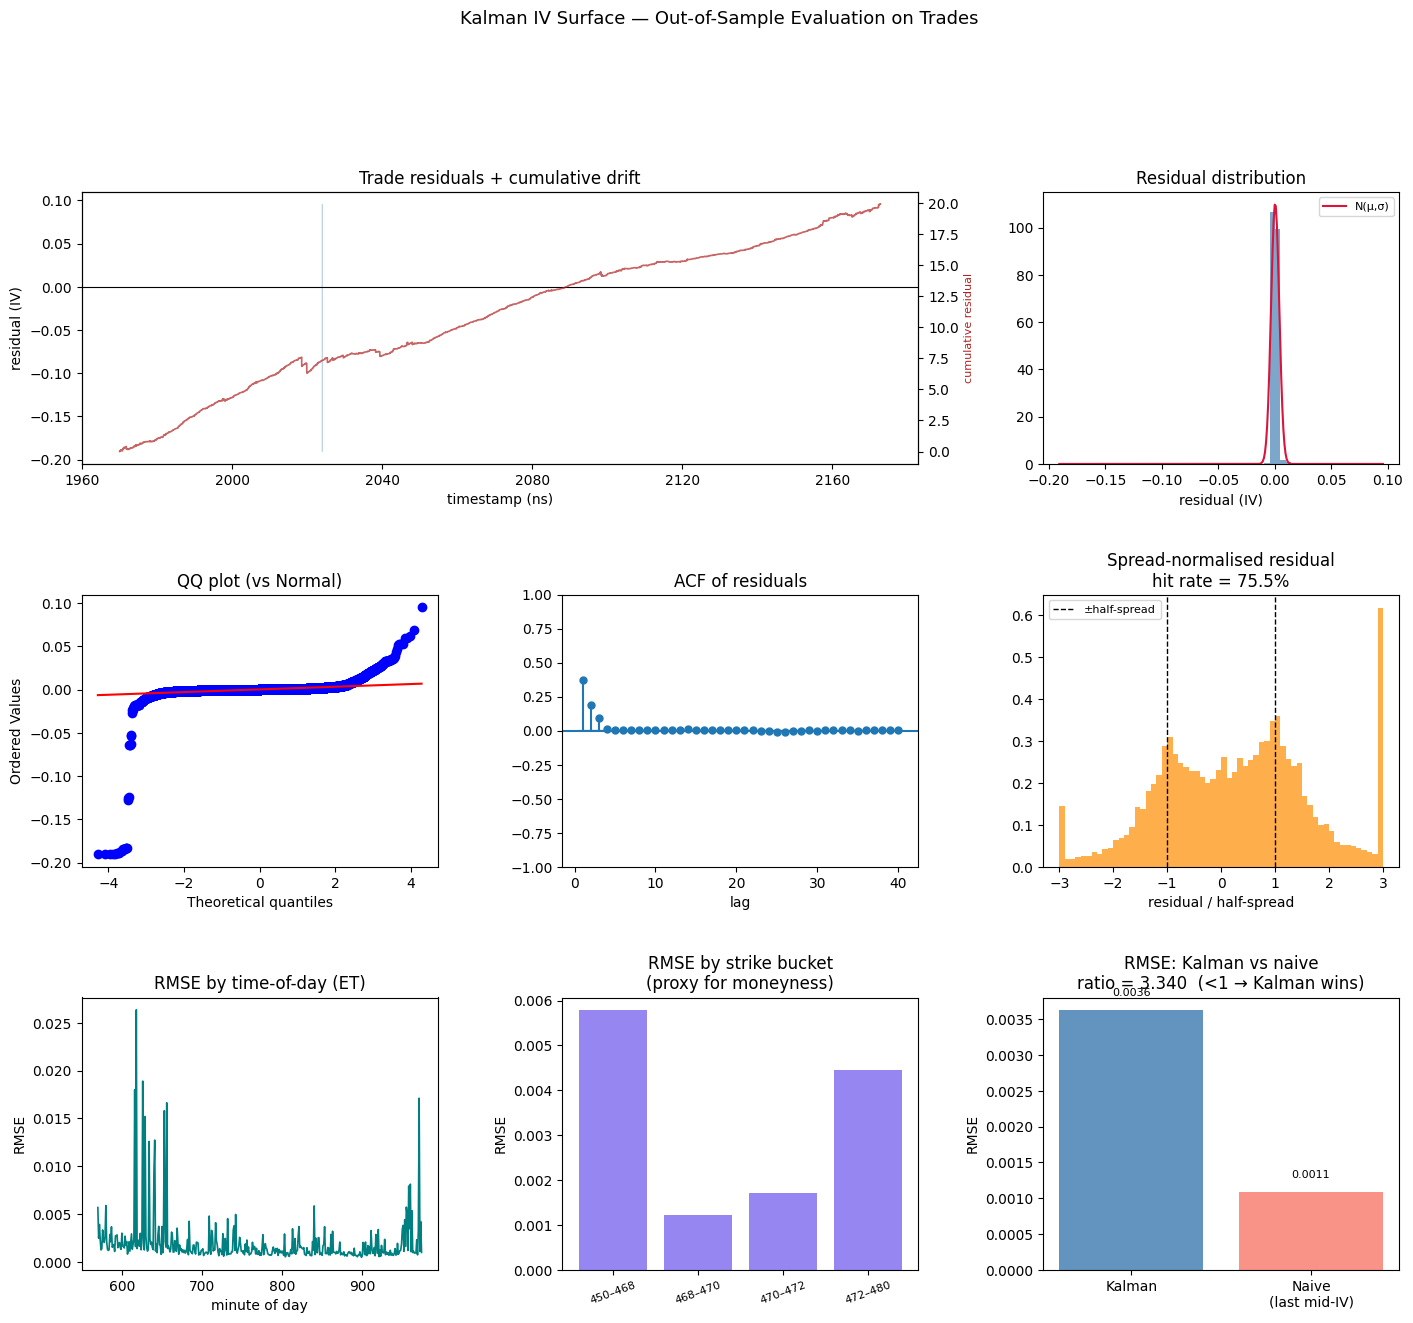

RMSE                 0.00362
MAE                  0.00090
Bias                 0.00027
Hit rate             75.5%
Naive RMSE           0.00108
RMSE ratio           3.340  (<1 = Kalman beats naive)

Ljung-Box (H0: no autocorrelation in residuals):
         lb_stat  lb_pvalue
10  13902.262238        0.0
20  13929.344663        0.0


In [40]:
metrics_fam = evaluate_kalman_iv(
    df_quotes_iv=df_quotes_fam.rename({"family_iv": "kalman_iv"}),
    df_trades_iv=df_trades_fam.rename({"family_matched": "kalman_matched"}),
)

## Benchmark — family vs SVI-only vs individual per-option KF

In [41]:
# ── SVI-only baseline (same backbone, no β) ───────────────────────────────────
df_quotes_svi, df_trades_svi, _ = surface_kalman_filters.run_spline_surface_kalman(
    df_quotes_iv=df_quotes_otm,
    df_trades_iv=df_trades_iv,
    cfg=svi_cfg,
)
df_trades_svi_clean = df_trades_svi.filter(
    pl.all_horizontal(pl.all().is_not_null()) & pl.all_horizontal(cs.float().is_not_nan())
)
rmse_svi = float((df_trades_svi_clean["trade_residual"] ** 2).mean() ** 0.5)

# ── Individual per-option KF baseline ────────────────────────────────────────
df_quotes_indiv, df_trades_indiv = kalman_filters.build_iv_surface(
    df_tickers=df_tickers,
    trade_date=trade_date,
    df_spy=df_spy,
    min_trades=100,
)
df_trades_indiv_clean = df_trades_indiv.filter(
    pl.all_horizontal(pl.all().is_not_null()) & pl.all_horizontal(cs.float().is_not_nan())
)
rmse_indiv = float((df_trades_indiv_clean["trade_residual"] ** 2).mean() ** 0.5)

O:SPY240105C00469000: dropping 2 bad quotes (crossed×2 (first=2024-01-03 11:49:45.633413-05:00))
O:SPY240105C00472000: dropping 1 bad quotes (crossed×1 (first=2024-01-03 15:51:02.275318-05:00))
O:SPY240105C00473000: dropping 1 bad quotes (crossed×1 (first=2024-01-03 10:29:17.744517-05:00))
O:SPY240105C00474000: dropping 4 bad quotes (crossed×4 (first=2024-01-03 10:25:56.925706-05:00))
O:SPY240105C00475000: dropping 1 bad quotes (crossed×1 (first=2024-01-03 14:02:06.496803-05:00))
O:SPY240105C00477000: dropping 1 bad quotes (crossed×1 (first=2024-01-03 10:00:44.569057-05:00))
O:SPY240105C00481000: dropping 46 bad quotes (sub-tick bid×46 (first=2024-01-03 16:00:02.443177-05:00))
O:SPY240105C00482000: dropping 64 bad quotes (sub-tick bid×64 (first=2024-01-03 10:00:01.421753-05:00))
O:SPY240105C00483000: dropping 842 bad quotes (sub-tick bid×842 (first=2024-01-03 09:30:00.060278-05:00), zero bid size×1 (first=2024-01-03 09:30:00.060278-05:00))
O:SPY240105C00484000: dropping 2129 bad quotes

In [42]:
print(f"{'Model':<40} {'RMSE (IV)':>12}   {'vs SVI-only':>12}")
print("-" * 68)
print(f"{'Individual per-option KF  (ceiling)':<40} {rmse_indiv:>12.5f}   {'—':>12}")
print(f"{'SVI-only Kalman           (baseline)':<40} {rmse_svi:>12.5f}   {'—':>12}")
print(
    f"{'Family: SVI + dynamic Δ(k,t)        ':<40} {rmse_fam:>12.5f}   {(rmse_fam / rmse_svi - 1) * 100:>+11.1f}%"
)
print()
print(f"Family vs individual KF: {rmse_fam / rmse_indiv:.3f}  (<1.00 → family wins)")
print(
    f"Gap closure: {(rmse_svi - rmse_fam) / (rmse_svi - rmse_indiv) * 100:.1f}% of SVI→indiv gap recovered"
)

Model                                       RMSE (IV)    vs SVI-only
--------------------------------------------------------------------
Individual per-option KF  (ceiling)           0.00274              —
SVI-only Kalman           (baseline)          0.00362              —
Family: SVI + dynamic Δ(k,t)                  0.00362          -0.0%

Family vs individual KF: 1.320  (<1.00 → family wins)
Gap closure: 0.0% of SVI→indiv gap recovered


## Residual distribution — family vs SVI-only

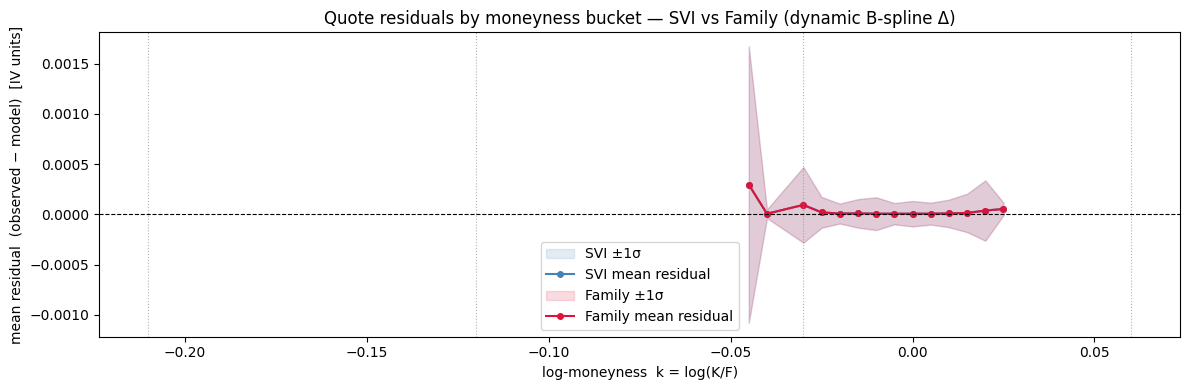

In [43]:
bin_w = 0.005


def _bin_residuals(df_quotes: pl.DataFrame, iv_col: str, label: str):
    """Return (k_centers, mean_residuals, std_residuals, n) for plotting."""
    df_clean = df_quotes.filter(
        pl.col("observed_iv").is_not_nan()
        & pl.col("observed_iv").is_not_null()
        & pl.col(iv_col).is_not_nan()
        & pl.col(iv_col).is_not_null()
        & pl.col("log_moneyness").is_not_nan()
    ).with_columns((pl.col("observed_iv") - pl.col(iv_col)).alias("residual"))
    df_agg = (
        df_clean.with_columns(
            ((pl.col("log_moneyness") / bin_w).round(0) * bin_w).alias("k_center")
        )
        .group_by("k_center")
        .agg(
            pl.col("residual").mean().alias("mean"),
            pl.col("residual").std().alias("std"),
            pl.col("residual").count().alias("n"),
        )
        .filter(pl.col("n") >= 100)
        .sort("k_center")
    )
    return df_agg["k_center"].to_numpy(), df_agg["mean"].to_numpy(), df_agg["std"].to_numpy()


k_svi, mu_svi, sig_svi = _bin_residuals(df_quotes_svi, "spline_iv", "SVI-only")
k_fam, mu_fam, sig_fam = _bin_residuals(df_quotes_fam, "family_iv", "Family")

fig, ax = plt.subplots(figsize=(12, 4))

ax.fill_between(
    k_svi, mu_svi - sig_svi, mu_svi + sig_svi, alpha=0.15, color="steelblue", label="SVI ±1σ"
)
ax.plot(k_svi, mu_svi, "o-", color="steelblue", ms=4, lw=1.5, label="SVI mean residual")

ax.fill_between(
    k_fam, mu_fam - sig_fam, mu_fam + sig_fam, alpha=0.15, color="crimson", label="Family ±1σ"
)
ax.plot(k_fam, mu_fam, "o-", color="crimson", ms=4, lw=1.5, label="Family mean residual")

# Interior knot positions
for k_knot in bspline_interior_knots:
    ax.axvline(k_knot, color="grey", lw=0.8, ls=":", alpha=0.6)

ax.axhline(0, color="black", lw=0.8, ls="--")
ax.set_xlabel("log-moneyness  k = log(K/F)")
ax.set_ylabel("mean residual  (observed − model)  [IV units]")
ax.set_title("Quote residuals by moneyness bucket — SVI vs Family (dynamic B-spline Δ)")
ax.legend()
plt.tight_layout()
plt.show()

In [44]:
import residual_diagnostics

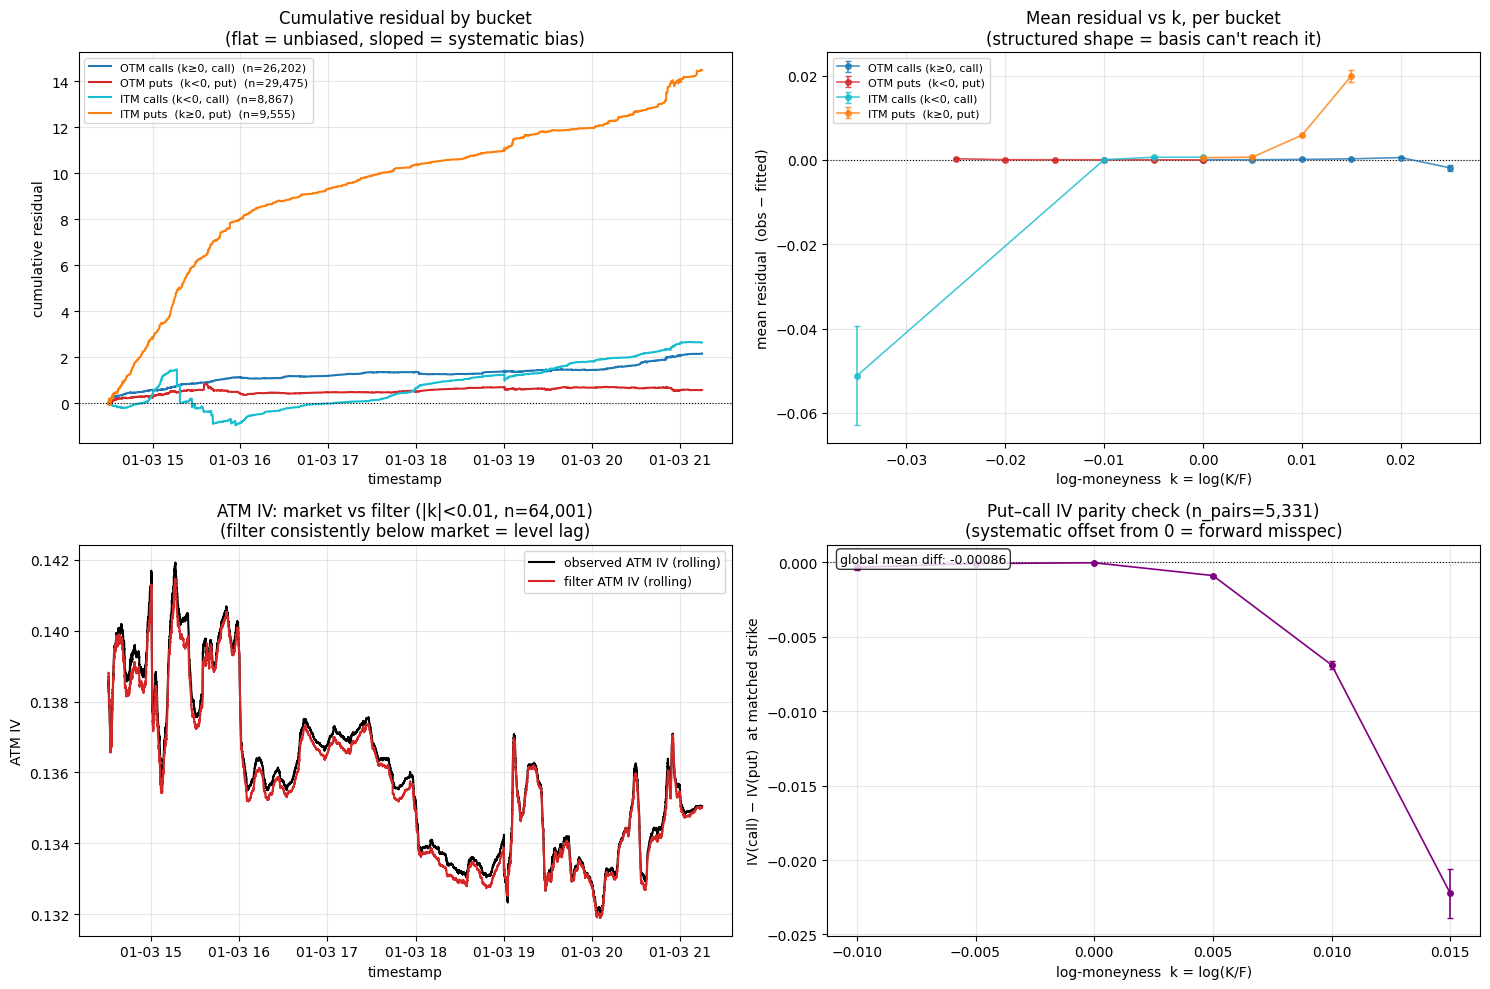

Residual summary by bucket
Bucket                               n        mean         std        RMSE
----------------------------------------------------------------------
OTM calls (k≥0, call)           26,202     0.00008     0.00081     0.00081
OTM puts  (k<0, put)            29,475     0.00002     0.00080     0.00080
ITM calls (k<0, call)            8,867     0.00030     0.00852     0.00853
ITM puts  (k≥0, put)             9,555     0.00152     0.00531     0.00552
----------------------------------------------------------------------
ALL                             74,099     0.00027     0.00361     0.00362


In [45]:
residual_diagnostics.plot_residual_diagnostics(df_trades_fam)

## Gatheral (2006) butterfly arbitrage check — family filter IV surface

For each timestamp we reconstruct the full smile from the Kalman state, then evaluate the Gatheral (2006) no-butterfly-arbitrage condition in total-variance space:

$$g(k) = \left(1 - \frac{k\,w'}{2w}\right)^2 - \frac{w'^2}{4}\!\left(\frac{1}{w} + \frac{1}{4}\right) + \frac{w''}{2} \geq 0 \;\; \forall k$$

where $w(k) = \sigma^2(k)\cdot T$ is the total implied variance.  $g < 0$ anywhere means butterfly arbitrage.

The whole check is **vectorised** across all timestamps — no Python loop over rows.

In [57]:
# ── 1. Subsample state history — check every SUBSAMPLE-th quote ───────────────
SUBSAMPLE = 1  # all samples  # ~1 check per ~2 sec of intraday quotes
idx = np.arange(0, len(df_state_fam), SUBSAMPLE)
df_arb_states = df_state_fam[idx]
# T is aligned by row (df_quotes_fam and df_state_fam share the same sort order)
tte_arr = df_quotes_fam[idx]["T"].to_numpy().astype(float)  # (n_rows,)
n_arb_rows = len(df_arb_states)

# ── 2. Extract SVI (θ) and B-spline (β) from state ───────────────────────────
states_mat = np.column_stack(
    [df_arb_states[f"state_{j}"].to_numpy() for j in range(n_total)]
)  # (n_rows, 13)
theta_mat = states_mat[:, :5]  # (n_rows, 5)  [a, b, rho, m, sigma]
beta_mat = states_mat[:, 5:]  # (n_rows, N_BASIS)

# ── 3. Dense k-grid covering the model domain ─────────────────────────────────
N_K = 300
k_arb = np.linspace(K_MIN, K_MAX, N_K)  # (N_K,)

# ── 4. B-spline design matrix — evaluated once (fixed geometry) ───────────────
k_arb_clamped = np.clip(k_arb, bspline_klo, bspline_khi)
B_arb = BSpline.design_matrix(k_arb_clamped, bspline_knots, DEGREE).toarray()  # (N_K, N_BASIS)

# ── 5. Vectorised SVI total variance  w_svi(k, t) ────────────────────────────
a_v, b_v, rho_v, m_v, sig_v = [theta_mat[:, i : i + 1] for i in range(5)]
sig_v = np.maximum(sig_v, 1e-6)

k2d = k_arb[np.newaxis, :]  # (1, N_K)
d = k2d - m_v  # (n_rows, N_K)
sq = np.sqrt(d**2 + sig_v**2)
w_svi = a_v + b_v * (rho_v * d + sq)  # SVI total variance  (n_rows, N_K)

# ── 6. SVI IV + B-spline correction → family total variance ──────────────────
T2d = tte_arr[:, np.newaxis]  # (n_rows, 1)
svi_iv = np.sqrt(np.maximum(w_svi, 0.0) / T2d)  # (n_rows, N_K)
delta_iv = beta_mat @ B_arb.T  # (n_rows, N_K)
fam_iv = np.maximum(svi_iv + delta_iv, 0.0)  # clip negatives
w_fam = fam_iv**2 * T2d  # total variance  (n_rows, N_K)

print(f"States subsampled : {n_arb_rows:,}  (every {SUBSAMPLE}th quote, k-grid {N_K} pts)")
print(f"w_fam shape       : {w_fam.shape}")

States subsampled : 978,523  (every 1th quote, k-grid 300 pts)
w_fam shape       : (978523, 300)


In [58]:
# ── 7. Gatheral g(k) — fully vectorised, no Python loop over timestamps ───────
w_safe = np.maximum(w_fam, 1e-10)
w1 = np.gradient(w_fam, k_arb, axis=1)  # dw/dk        (n_rows, N_K)
w2 = np.gradient(w1, k_arb, axis=1)  # d²w/dk²      (n_rows, N_K)

g = (
    (1.0 - k2d * w1 / (2.0 * w_safe)) ** 2  # term 1
    - (w1**2 / 4.0) * (1.0 / w_safe + 0.25)  # term 2
    + w2 / 2.0  # term 3
)  # (n_rows, N_K)

min_g = g.min(axis=1)  # (n_rows,) worst g across the smile
argmin_g = g.argmin(axis=1)  # (n_rows,) index of the worst violation
is_arb = min_g < 0  # True = butterfly arbitrage at this timestamp

n_bad = int(is_arb.sum())
pct_bad = is_arb.mean() * 100
worst_row = int(min_g.argmin())

print(f"Timestamps checked   : {n_arb_rows:,}")
print(f"Arbitrage-free       : {n_arb_rows - n_bad:,}  ({100 - pct_bad:.1f}%)")
print(f"Butterfly arbitrage  : {n_bad:,}  ({pct_bad:.1f}%)")
print(f"Min g (global worst) : {min_g.min():.5f}  at k = {k_arb[argmin_g[worst_row]]:.4f}")
print(f"Mean min_g           : {min_g.mean():.5f}")

Timestamps checked   : 978,523
Arbitrage-free       : 131,202  (13.4%)
Butterfly arbitrage  : 847,321  (86.6%)
Min g (global worst) : -0.62671  at k = -0.0833
Mean min_g           : -0.20802


In [59]:
# ts_arb = df_arb_states["ts_ns"].to_list()

# # ── Time series: min g(k, t) ──────────────────────────────────────────────────
# fig = make_subplots(
#     rows=2,
#     cols=1,
#     shared_xaxes=True,
#     vertical_spacing=0.06,
#     row_heights=[0.68, 0.32],
#     subplot_titles=[
#         "min g(k, t) — Gatheral butterfly check (red = arb)",
#         "Arbitrage flag",
#     ],
# )
# fig.add_trace(
#     go.Scatter(
#         x=ts_arb,
#         y=min_g.tolist(),
#         mode="lines",
#         line=dict(color="steelblue", width=1),
#         name="min g(k)",
#     ),
#     row=1,
#     col=1,
# )
# # Shade arbitrage periods in the min_g panel
# arb_mask = is_arb.astype(float)
# fig.add_trace(
#     go.Scatter(
#         x=ts_arb,
#         y=np.where(is_arb, min_g, np.nan).tolist(),
#         mode="markers",
#         marker=dict(color="crimson", size=3, opacity=0.6),
#         name="arb timestamps",
#     ),
#     row=1,
#     col=1,
# )
# fig.add_hline(
#     y=0,
#     line=dict(color="red", width=1.5, dash="dash"),
#     annotation_text="g = 0 (arb threshold)",
#     row=1,
#     col=1,
# )

# fig.add_trace(
#     go.Scatter(
#         x=ts_arb,
#         y=arb_mask.tolist(),
#         mode="lines",
#         line=dict(color="crimson", width=1),
#         fill="tozeroy",
#         fillcolor="rgba(220,50,47,0.15)",
#         name="is_arb",
#     ),
#     row=2,
#     col=1,
# )
# fig.update_layout(
#     title=f"Gatheral butterfly check — family filter  ({pct_bad:.1f}% of timestamps flagged)",
#     height=520,
#     legend=dict(x=1.01, y=1.0),
# )
# fig.update_yaxes(title_text="min g(k)", row=1, col=1)
# fig.update_yaxes(title_text="is_arb", tickvals=[0, 1], ticktext=["no", "yes"], row=2, col=1)
# fig.update_xaxes(title_text="Time", row=2, col=1)
# fig.show()

# # ── g(k) curve at 6 representative timestamps ─────────────────────────────────
# sample_idx = np.linspace(0, n_arb_rows - 1, 6, dtype=int)
# fig2 = go.Figure()
# for si in sample_idx:
#     si = int(si)  # Convert numpy.int64 to Python int
#     color = "crimson" if is_arb[si] else "steelblue"
#     label = (
#         f"{df_arb_states['ts_ns'][si].strftime('%H:%M:%S')}"
#         f"  {'[ARB]' if is_arb[si] else '[ok]'}"
#         f"  min_g={min_g[si]:.4f}"
#     )
#     fig2.add_trace(
#         go.Scatter(
#             x=k_arb.tolist(),
#             y=g[si].tolist(),
#             mode="lines",
#             line=dict(width=1.5, color=color),
#             name=label,
#         )
#     )
# fig2.add_hline(y=0, line=dict(color="black", width=1.5, dash="dash"), annotation_text="g = 0")
# fig2.update_layout(
#     title="g(k) curve at representative timestamps  (red = butterfly arb)",
#     xaxis_title="log-moneyness  k = log(K/F)",
#     yaxis_title="g(k)",
#     height=420,
#     legend=dict(x=1.01, y=1.0),
# )
# fig2.show()